<div dir="rtl" align="right">

## اجرای DBSCAN روی GPU

در این بخش از **cuML DBSCAN** و **GPU** برای خوشه‌بندی حدود ۵۹۱٬۳۹۵ رکورد استفاده شده است.  
به همین دلیل ابتدا `cp.cuda.set_allocator` فراخوانی شده و داده یک‌بار روی GPU قرار گرفته است تا در هر اجرا دوباره به GPU منتقل نشود.

</div>

In [1]:
import cuml
from cuml.cluster import DBSCAN
import cupy as cp
print('cuML:', cuml.__version__)
print('CUDA:', cp.cuda.runtime.runtimeGetVersion())
print('GPU count:', cp.cuda.runtime.getDeviceCount())
print('GPU name:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

cuML: 26.08.00
CUDA: 13020
GPU count: 1
GPU name: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
import numpy as np
import pandas as pd
import time
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_parquet("divar_clean.parquet")

In [4]:
display(df.head())
print(df.shape)

,cat2_slug,cat3_slug,city_slug,neighborhood_slug,created_at_month,user_type,rent_mode,rent_value,rent_type,price_mode,...,has_jacuzzi_filled,has_jacuzzi_source,has_sauna_prob,has_sauna_filled,has_sauna_source,has_barbecue_prob,has_barbecue_filled,has_barbecue_source,luxury_amenity_count_filled,has_luxury_amenity_filled
0,temporary-rent,villa,karaj,mehrshahr,2024-08-01,مشاور املاک,NaN,NaN,NaN,NaN,...,True,model,0.409585,True,model,0.129706,False,model,3,True
1,residential-sell,apartment-sell,tehran,gholhak,2024-05-01,مشاور املاک,NaN,NaN,NaN,مقطوع,...,<NA>,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,<NA>,<NA>
2,residential-rent,apartment-rent,tehran,tohid,2024-10-01,NaN,مقطوع,26000000.0,NaN,NaN,...,<NA>,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,<NA>,<NA>
3,commercial-rent,office-rent,tehran,elahiyeh,2024-06-01,NaN,مقطوع,95000000.0,NaN,NaN,...,<NA>,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,<NA>,<NA>
4,residential-sell,apartment-sell,mashhad,emamreza,2024-05-01,مشاور املاک,NaN,NaN,NaN,مقطوع,...,<NA>,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,<NA>,<NA>


(1000000, 127)


In [5]:
mask = (
    df["target_price"].notna() &
    ~df["is_duplicate"] &
    ~df["price_is_outlier"] &
    df["utm_x"].notna() &
    df["utm_y"].notna()
)

clean_df = df[mask].copy()

In [6]:
print(clean_df.shape)

(591395, 127)


In [7]:
clean_df["log_price"] = np.log10(clean_df["target_price"])
clean_df["utm_x_km"]  = clean_df["utm_x"] / 1000
clean_df["utm_y_km"]  = clean_df["utm_y"] / 1000

In [8]:
feature_cols = ["utm_x_km", "utm_y_km", "log_price"]
X = clean_df[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
import time
import numpy as np
import cupy as cp
from cuml.cluster import DBSCAN

def run_dbscan(X_gpu, eps, min_samples, max_mb=2048):
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        max_mbytes_per_batch=max_mb,
        output_type="numpy",
    )
    t0 = time.time()
    model.fit(X_gpu)
    elapsed = time.time() - t0
    labels = model.labels_.astype(np.int64)
    n_clusters = len(set(labels.tolist()) - {-1})
    noise_frac = float((labels == -1).mean())
    return labels, n_clusters, noise_frac, elapsed

In [10]:
print(X_scaled.shape, X_scaled.dtype)

(591395, 3) float64


In [11]:
import cupy as cp
# Faster memory allocation across fits
cp.cuda.set_allocator(cp.cuda.MemoryPool().malloc)

# Pre-allocate the input array on GPU once — avoids re-uploading 591k rows every fit
X_gpu = cp.asarray(X_scaled)
print('Input on GPU:', X_gpu.shape, X_gpu.dtype)

Input on GPU: (591395, 3) float64


In [ ]:
import pandas as pd
import cupy as cp

X_gpu = cp.asarray(X_scaled) if not isinstance(X_scaled, cp.ndarray) else X_scaled
cp.cuda.set_allocator(cp.cuda.MemoryPool().malloc)

results = []
for eps in [0.55, 0.70, 0.85, 1.00]:
    labels = None
    try:
        print(f"→ eps={eps:<4} ms=50", end="", flush=True)
        labels, n, noise, secs = run_dbscan(X_gpu, eps, 50)
        results.append({"eps": eps, "n": n,
                        "noise": round(noise, 3), "secs": round(secs, 1)})
        print(f"   clusters={n:<3} noise={noise:>5.1%} {secs:>6.0f}s")
    except Exception as e:
        print(f"   Error: {str(e)[:60]}")
    finally:
        if labels is not None: del labels
        cp.get_default_memory_pool().free_all_blocks()

display(pd.DataFrame(results))

→ eps=0.55 ms=50   clusters=4   noise= 0.0%    457s
→ eps=0.7  ms=50   clusters=2   noise= 0.0%    508s
→ eps=0.85 ms=50

<div dir="rtl" align="right">

## نتیجه غیرمنتظره: نویز صفر و زمان اجرای بالا

با وجود استفاده از **GPU**، هر اجرای DBSCAN حدود ۴۵۰ تا ۵۰۰ ثانیه طول کشیده است.  
نکته عجیب‌تر این است که تقریباً در همه‌ی epsها نویز برابر **۰.۰٪** گزارش شده و تعداد خوشه‌ها بسیار کم است.  
این با انتظار معمول از DBSCAN متفاوت است؛ چون DBSCAN معمولاً باید نقاط پرت را به‌عنوان نویز علامت بزند و مناطق چگال را از هم جدا کند.

</div>

In [12]:
labels, n, noise, secs = run_dbscan(X_scaled, 0.62, 50)
print(f"eps=0.62 → {n} clusters, {noise:.1%} noise, {secs:.0f}s")

eps=0.62 → 2 clusters, 0.0% noise, 473s


In [14]:
labels, n, noise, secs = run_dbscan(X_scaled, 0.58, 50)
print(f"eps=0.58 → {n} clusters, {noise:.1%} noise, {secs:.0f}s")

eps=0.58 → 4 clusters, 0.0% noise, 462s


In [16]:
labels, n, noise, secs = run_dbscan(X_scaled, 0.60, 50)
print(f"eps=0.60 → {n} clusters, {noise:.1%} noise, {secs:.0f}s")

eps=0.60 → 3 clusters, 0.0% noise, 467s


<div dir="rtl" align="right">

## نتیجه غیرمنتظره‌ی اصلی: یک خوشه غول‌آسا

با `eps=0.60` و `min_samples=50`، از ۵۹۱٬۳۹۵ نقطه، **۵۹۱٬۰۲۰ نقطه** در یک خوشه‌ی واحد قرار گرفته‌اند.  
فقط ۱۹۰ نقطه نویز و دو خوشه‌ی بسیار کوچک با ۱۲۷ و ۵۸ نقطه شناسایی شده است.  
یعنی DBSCAN تقریباً همه‌ی داده را یک منطقه‌ی بزرگ دیده و تفکیک معناداری انجام نداده است.  
این اجرا هم با **GPU** انجام شده و حدود ۴۷۱ ثانیه طول کشیده است.

</div>

In [20]:
import cupy as cp

best_eps = 0.60
best_ms  = 50

# Free GPU memory before the final fit
cp.get_default_memory_pool().free_all_blocks()

labels, n_clusters, noise_frac, secs = run_dbscan(X_scaled, best_eps, best_ms)

clean_df["cluster"] = labels

print(f"eps={best_eps}, ms={best_ms} → {n_clusters} clusters, {noise_frac:.1%} noise, {secs:.0f}s")
print("\nCluster sizes:")
print(clean_df["cluster"].value_counts().sort_index())

eps=0.6, ms=50 → 3 clusters, 0.0% noise, 471s

Cluster sizes:
cluster
-1       190
 0    591020
 1       127
 2        58
Name: count, dtype: int64


In [21]:
def top_city(series):
    vc = series.value_counts()
    return vc.index[0] if len(vc) > 0 else "—"

def top_cities(series, k=3):
    vc = series.value_counts().head(k)
    return ", ".join(f"{c} ({n})" for c, n in vc.items())

summary = (
    clean_df.groupby("cluster")
            .agg(
                n             = ("log_price",    "size"),
                median_price  = ("target_price", "median"),
                mean_price    = ("target_price", "mean"),
                mean_x_km     = ("utm_x_km",     "mean"),
                mean_y_km     = ("utm_y_km",     "mean"),
                top_city      = ("city_slug",    top_city),
                top_3_cities  = ("city_slug",    top_cities),
            )
            .round(0)
)
display(summary)

,n,median_price,mean_price,mean_x_km,mean_y_km,top_city,top_3_cities
cluster,,,,,,,
-1,190,5.750000e+06,6.077300e+11,955.0,3466.0,zahedan,"zahedan (42), kish (11), birjand (10)"
0,591020,1.566667e+09,4.411594e+09,561.0,3880.0,tehran,"tehran (134350), mashhad (34744), karaj (34235)"
1,127,6.509500e+05,1.038924e+06,1076.0,3342.0,kerman,"kerman (93), baft (6), rafsanjan (6)"
2,58,6.000000e+05,7.551930e+05,1475.0,2832.0,chabahar,"chabahar (56), konarak (2), Iranshahr (0)"


In [22]:
import cupy as cp
cp.get_default_memory_pool().free_all_blocks()

labels_8, n8, noise8, secs8 = run_dbscan(X_scaled, 0.35, 50)
clean_df["cluster_8"] = labels_8

print(f"eps=0.35 ms=50 → {n8} clusters, {noise8:.1%} noise, {secs8:.0f}s")
print("\nCluster sizes:")
print(clean_df["cluster_8"].value_counts().sort_index())

eps=0.35 ms=50 → 8 clusters, 0.3% noise, 383s

Cluster sizes:
cluster_8
-1      1587
 0    582722
 1      1067
 2      4259
 3       571
 4       149
 5       726
 6       237
 7        77
Name: count, dtype: int64


In [23]:
centroids = (
    clean_df[clean_df["cluster_8"] != -1]
    .groupby("cluster_8")
    .agg(
        n             = ("log_price",    "size"),
        median_price  = ("target_price", "median"),
        mean_x_km     = ("utm_x_km",     "mean"),
        mean_y_km     = ("utm_y_km",     "mean"),
        top_city      = ("city_slug",    lambda s: s.value_counts().index[0]),
    )
    .round(0)
    .sort_values("n", ascending=False)
)
display(centroids)

,n,median_price,mean_x_km,mean_y_km,top_city
cluster_8,,,,,
0,582722,1.600000e+09,551.0,3887.0,tehran
2,4259,6.166667e+08,1474.0,3279.0,zahedan
1,1067,5.000000e+05,1262.0,4054.0,mashhad
5,726,7.000000e+05,604.0,3288.0,shiraz
3,571,8.666667e+08,1475.0,2833.0,chabahar
6,237,8.000000e+05,1018.0,3002.0,qeshm
4,149,4.000000e+05,817.0,3532.0,yazd
7,77,5.000000e+05,1082.0,3357.0,kerman


In [24]:
import cupy as cp
cp.get_default_memory_pool().free_all_blocks()

labels_test, n_test, noise_test, secs = run_dbscan(X_scaled, 0.35, 2000)

print(f"eps=0.35, ms=2000 → {n_test} clusters, {noise_test:.1%} noise, {secs:.0f}s")
print("\nCluster sizes:")
print(pd.Series(labels_test).value_counts().sort_index())

eps=0.35, ms=2000 → 6 clusters, 9.4% noise, 328s

Cluster sizes:
-1     55586
 0    450224
 1     41108
 2     14106
 3     25186
 4      2902
 5      2283
Name: count, dtype: int64


<div dir="rtl" align="right">

## نتیجه بهتر با min_samples بزرگ‌تر

وقتی `eps=0.35` و `min_samples=2000` انتخاب شد، نتیجه منطقی‌تر شد:  
۶ خوشه و **۹.۴٪ نویز** شناسایی شد.  
این نشان می‌دهد که برای این داده‌ی بزرگ، افزایش `min_samples` به DBSCAN کمک می‌کند تا خوشه‌های کوچک و تصادفی را نویز در نظر بگیرد.  
این بخش نیز با **GPU** اجرا شده است.

</div>

In [25]:
import pandas as pd

if 'labels_test' in dir():
    temp = clean_df.copy()
    temp['cluster_check'] = labels_test
    
    centroids = (
        temp[temp['cluster_check'] != -1]
        .groupby('cluster_check')
        .agg(
            n            = ('log_price', 'size'),
            mean_x_km    = ('utm_x_km', 'mean'),
            mean_y_km    = ('utm_y_km', 'mean'),
            top_city     = ('city_slug', lambda s: s.value_counts().index[0]),
            top_3        = ('city_slug', lambda s: ', '.join(s.value_counts().head(3).index)),
        )
        .round(0)
        .sort_values('n', ascending=False)
    )
    display(centroids)
else:
    print("labels_test not in memory — skip this, run the fit below instead")

,n,mean_x_km,mean_y_km,top_city,top_3
cluster_check,,,,,
0,450224,470.0,3953.0,tehran,"tehran, karaj, isfahan"
1,41108,1254.0,4052.0,mashhad,"mashhad, neyshabur, sabzevar"
3,25186,630.0,3289.0,shiraz,"shiraz, sadra, yasuj"
2,14106,281.0,3478.0,ahvaz,"ahvaz, dezful, abadan"
4,2902,1070.0,3366.0,kerman,"kerman, rafsanjan, zarand"
5,2283,1026.0,3016.0,bandar-abbas,"bandar-abbas, qeshm, minab"


In [26]:
import cupy as cp
cp.get_default_memory_pool().free_all_blocks()

# Isolate cluster 0's points
mask0 = labels_test == 0
X_sub = X_scaled[mask0]
print(f"Re-clustering {mask0.sum():,} points...")

# Tighter eps, higher min_samples
sub_labels, n_sub, noise_sub, secs = run_dbscan(X_sub, eps=0.20, min_samples=2000)
print(f"→ {n_sub} sub-clusters, {noise_sub:.1%} noise, {secs:.0f}s")
print(pd.Series(sub_labels).value_counts().sort_index())

Re-clustering 450,224 points...
→ 4 sub-clusters, 20.7% noise, 168s
-1     93239
 0    289007
 1     27814
 2     14347
 3     25817
Name: count, dtype: int64


<div dir="rtl" align="right">

## خوشه‌بندی مجدد فقط روی خوشه‌ی غول‌آسا

چون خوشه‌ی صفر تقریباً همه‌ی داده را در خود گرفته بود، همان خوشه به‌تنهایی و با تنظیمات سخت‌گیرانه‌تر (`eps=0.20`, `min_samples=2000`) دوباره خوشه‌بندی شد.  
این اجرا با **GPU** انجام شد و به ۴ زیرخوشه رسید.  
حدود ۲۰.۷٪ از نقاط این زیرمجموعه نویز تشخیص داده شدند.  
این زیرخوشه‌ها تقریباً همان مناطق تهران، اصفهان، رشت و تبریز را نشان می‌دهند.

</div>

In [27]:
import pandas as pd
import numpy as np

temp = clean_df.loc[mask0].copy()
temp['sub'] = sub_labels

centroids = (
    temp[temp['sub'] != -1]
    .groupby('sub')
    .agg(
        n           = ('log_price', 'size'),
        mean_x_km   = ('utm_x_km', 'mean'),
        mean_y_km   = ('utm_y_km', 'mean'),
        top_city    = ('city_slug', lambda s: s.value_counts().index[0]),
        top_3       = ('city_slug', lambda s: ', '.join(s.value_counts().head(3).index)),
        median_price= ('target_price', 'median'),
    )
    .round(0)
    .sort_values('n', ascending=False)
)
display(centroids)

,n,mean_x_km,mean_y_km,top_city,top_3,median_price
sub,,,,,,
0,289007,529.0,3960.0,tehran,"tehran, karaj, andisheh-new-town",1.950000e+09
1,27814,556.0,3611.0,isfahan,"isfahan, najafabad, shahin-shahr",1.872500e+09
3,25817,383.0,4126.0,rasht,"rasht, lahijan, bandar-anzali",1.850000e+09
2,14347,85.0,4222.0,tabriz,"tabriz, sahand, marand",1.583333e+09


In [ ]:
import numpy as np
import pandas as pd

# ---- Reconstruct the full label array ----
final = labels_test.copy()                    # outer 6-cluster result (591k rows)

sub_offset = sub_labels.copy()
sub_offset[sub_offset != -1] += 100           # sub-0 → 100, sub-1 → 101, ...
sub_offset[sub_offset == -1] = -1
final[mask0] = sub_offset

# ---- Map 9 clusters → 3 macro-regions ----
mapping = {
    # Region 0 — CENTRAL (Tehran + Isfahan)
    100: 0,      # sub-0  Tehran
    101: 0,      # sub-1  Isfahan

    # Region 1 — NORTH (Caspian + NW + NE)
    102: 1,      # sub-2  Tabriz
    103: 1,      # sub-3  Rasht
    1:   1,      # outer-1 Mashhad

    # Region 2 — SOUTH (Fars, Khuzestan, Kerman, Hormozgan)
    3:   2,      # outer-3 Shiraz
    2:   2,      # outer-2 Ahvaz
    4:   2,      # outer-4 Kerman
    5:   2,      # outer-5 Bandar Abbas

    -1: -1,
}

clean_df['cluster'] = (
    pd.Series(final)
      .map(mapping)
      .fillna(-1)
      .astype('int64')
      .values
)

print(clean_df['cluster'].value_counts().sort_index())
print(f"\nTotal rows: {len(clean_df):,}")
print(f"Noise fraction: {(clean_df['cluster'] == -1).mean():.1%}")

cluster
-1    148825
 0    316821
 1     81272
 2     44477
Name: count, dtype: int64

Total rows: 591,395
Noise fraction: 25.2%


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Train on the sub-fit's non-noise points
X_sub = X_scaled[mask0]
labeled = sub_labels != -1

clf = KNeighborsClassifier(n_neighbors=5, n_jobs=-1, weights='distance')
clf.fit(X_sub[labeled], sub_labels[labeled])

# Predict for the sub-fit's noise points, add 100 to match the offset
predicted = clf.predict(X_sub[~labeled]) + 100
sub_filled = sub_offset.copy()
sub_filled[sub_labels == -1] = predicted

# Rebuild final
final = labels_test.copy()
final[mask0] = sub_filled

# Re-apply mapping (with .values!)
clean_df['cluster'] = (
    pd.Series(final)
      .map(mapping)
      .fillna(-1)
      .astype('int64')
      .values
)

print(clean_df['cluster'].value_counts().sort_index())
print(f"Noise: {(clean_df['cluster'] == -1).mean():.1%}")

cluster
-1     55586
 0    383792
 1    107540
 2     44477
Name: count, dtype: int64
Noise: 9.4%


<div dir="rtl" align="right">

## پر کردن نویز با KNN

برای اینکه نقاط نویز از دست نروند، با یک طبقه‌بند **KNN** از کتابخانه‌ی `sklearn` به هر نقطه‌ی نویز، نزدیک‌ترین زیرخوشه نسبت داده شد.  
این مرحله روی **CPU** انجام شده است.  
بعد از این کار، نویز نهایی به حدود **۹.۴٪** کاهش پیدا کرد و سه منطقه‌ی کلان به دست آمد.

</div>

In [31]:
def top_cities(s, k=3):
    return ', '.join(f"{c} ({n})" for c, n in s.value_counts().head(k).items())

summary = (
    clean_df[clean_df['cluster'] != -1]
    .groupby('cluster')
    .agg(
        n             = ('log_price', 'size'),
        median_price  = ('target_price', 'median'),
        mean_x_km     = ('utm_x_km', 'mean'),
        mean_y_km     = ('utm_y_km', 'mean'),
        top_3_cities  = ('city_slug', top_cities),
    )
    .round(0)
)
display(summary)

,n,median_price,mean_x_km,mean_y_km,top_3_cities
cluster,,,,,
0,383792,1.800000e+09,511.0,3917.0,"tehran (132912), karaj (33723), isfahan (21617)"
1,107540,1.416667e+09,621.0,4117.0,"mashhad (33244), tabriz (14598), rasht (10802)"
2,44477,1.150000e+09,568.0,3340.0,"shiraz (16699), ahvaz (7604), kerman (2432)"


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

# Display subsample (591k points on screen is unreadable + slow)
plot_df = clean_df.sample(30_000, random_state=0).copy()

CLUSTER_NAMES = {
    -1: "noise",
     0: "Central (Tehran + Isfahan)",
     1: "North (Caspian + NW + NE)",
     2: "South (Fars + Khuzestan + Kerman)",
}

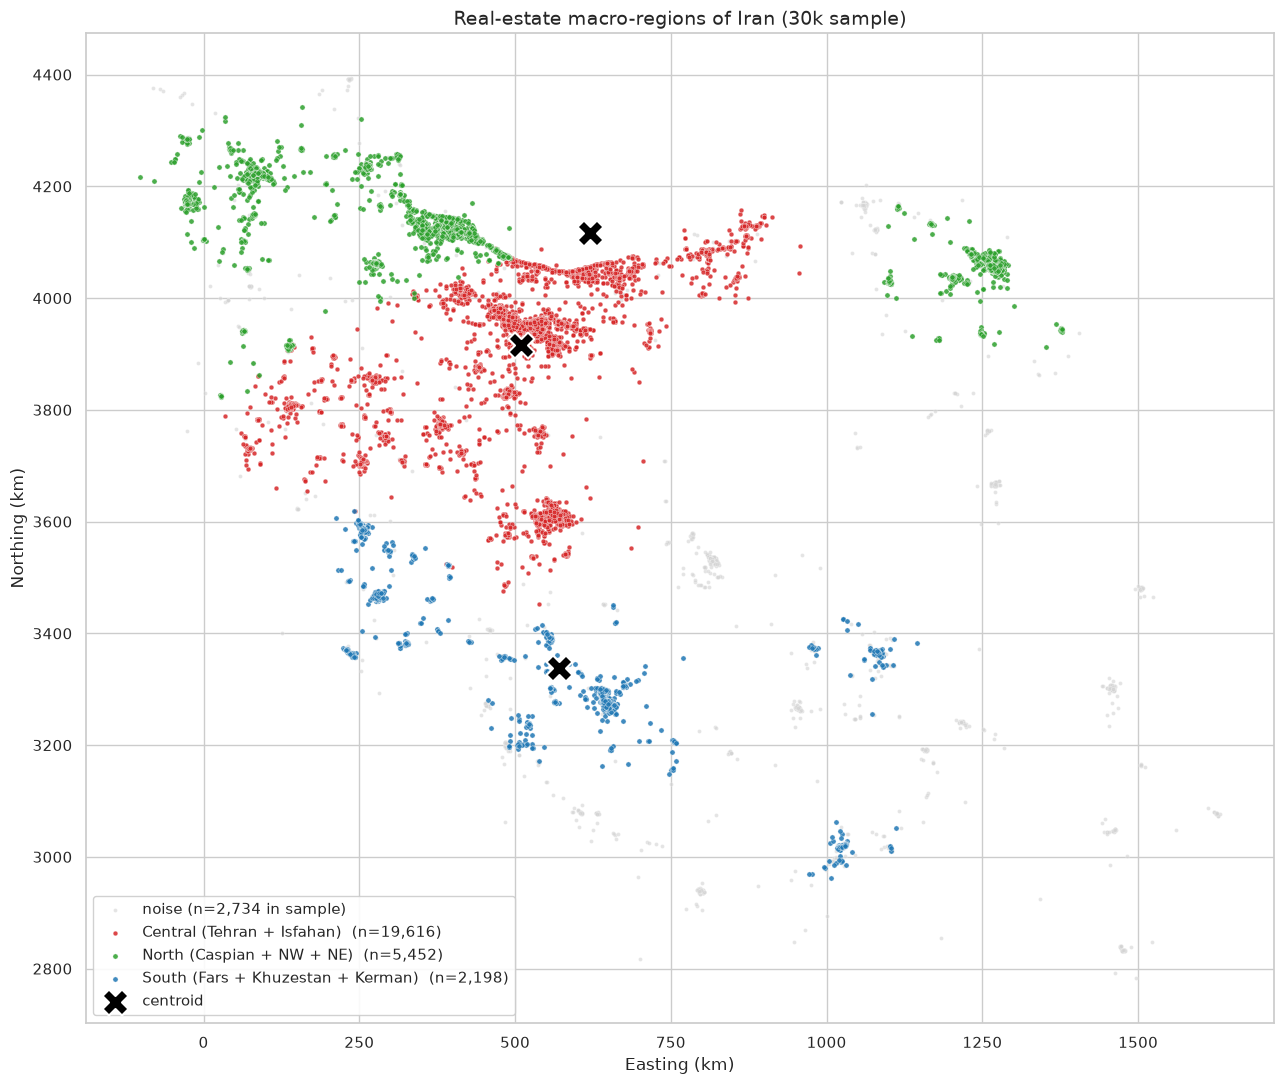

In [35]:
plt.figure(figsize=(13, 11))

# Noise first, so it's drawn under the clusters
noise = plot_df[plot_df["cluster"] == -1]
sns.scatterplot(data=noise, x="utm_x_km", y="utm_y_km",
                color="lightgray", s=8, alpha=0.6,
                label=f"noise (n={len(noise):,} in sample)")

# Cluster colors
palette = {-1: "lightgray", 0: "#d62728", 1: "#2ca02c", 2: "#1f77b4"}
size    = {-1: 8, 0: 12, 1: 14, 2: 14}

for cid in [0, 1, 2]:
    sub = plot_df[plot_df["cluster"] == cid]
    sns.scatterplot(data=sub, x="utm_x_km", y="utm_y_km",
                    color=palette[cid], s=size[cid], alpha=0.85,
                    label=f"{CLUSTER_NAMES[cid]}  (n={len(sub):,})")

# Cluster centroids as black X markers
centroids = plot_df[plot_df["cluster"] != -1].groupby("cluster")[["utm_x_km", "utm_y_km"]].mean()
plt.scatter(centroids["utm_x_km"], centroids["utm_y_km"],
            marker="X", s=350, c="black", edgecolor="white",
            linewidth=1.5, zorder=10, label="centroid")

plt.xlabel("Easting (km)", fontsize=12)
plt.ylabel("Northing (km)", fontsize=12)
plt.title("Real-estate macro-regions of Iran (30k sample)", fontsize=14)
plt.legend(loc="lower left", framealpha=0.9)
plt.tight_layout()
plt.show()

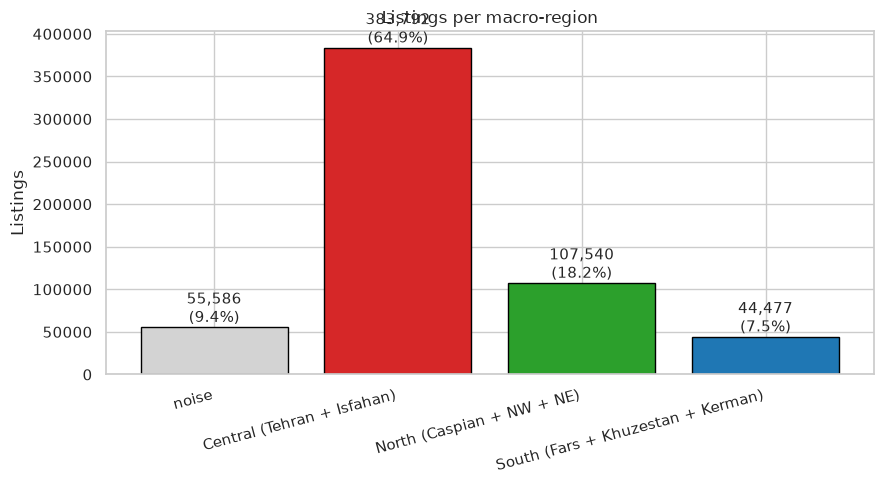

In [36]:
sizes = clean_df["cluster"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
colors = [palette.get(c, "gray") for c in sizes.index]
bars = plt.bar([CLUSTER_NAMES.get(c, str(c)) for c in sizes.index],
               sizes.values, color=colors, edgecolor="black")

# Count + percentage labels on top of each bar
total = sizes.sum()
for bar, v in zip(bars, sizes.values):
    plt.text(bar.get_x() + bar.get_width()/2, v,
             f"{v:,}\n({v/total:.1%})",
             ha="center", va="bottom", fontsize=11)

plt.ylabel("Listings")
plt.title("Listings per macro-region")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

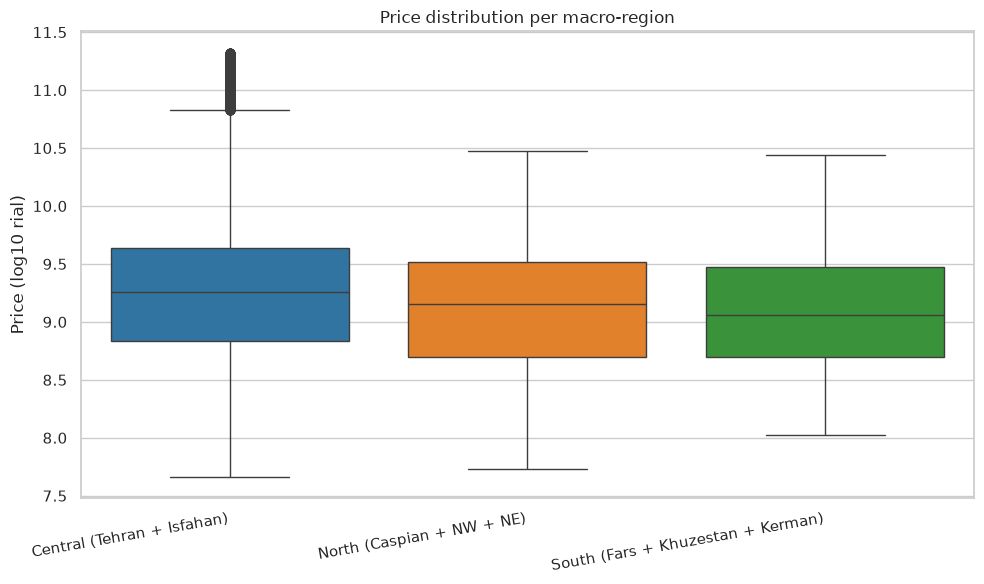

In [37]:
plot_data = clean_df[clean_df["cluster"] != -1][["cluster", "log_price"]].copy()
plot_data["region"] = plot_data["cluster"].map(CLUSTER_NAMES)

plt.figure(figsize=(10, 6))
sns.boxplot(data=plot_data, x="region", y="log_price",
            hue="region", palette="tab10", legend=False)

plt.xlabel("")
plt.ylabel("Price (log10 rial)")
plt.title("Price distribution per macro-region")
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

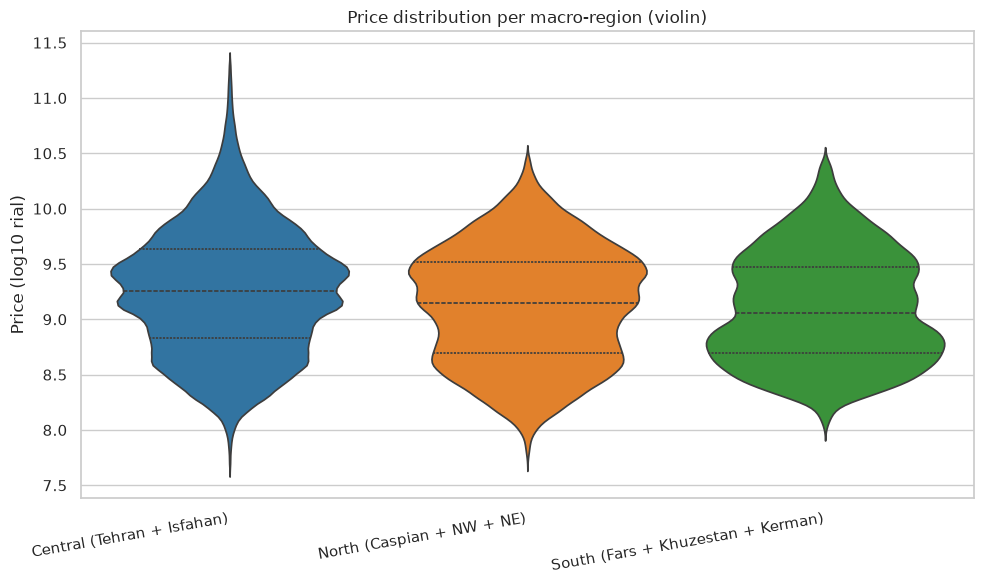

In [38]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=plot_data, x="region", y="log_price",
               hue="region", palette="tab10",
               inner="quartile", legend=False)

plt.xlabel("")
plt.ylabel("Price (log10 rial)")
plt.title("Price distribution per macro-region (violin)")
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2071/2088451775.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


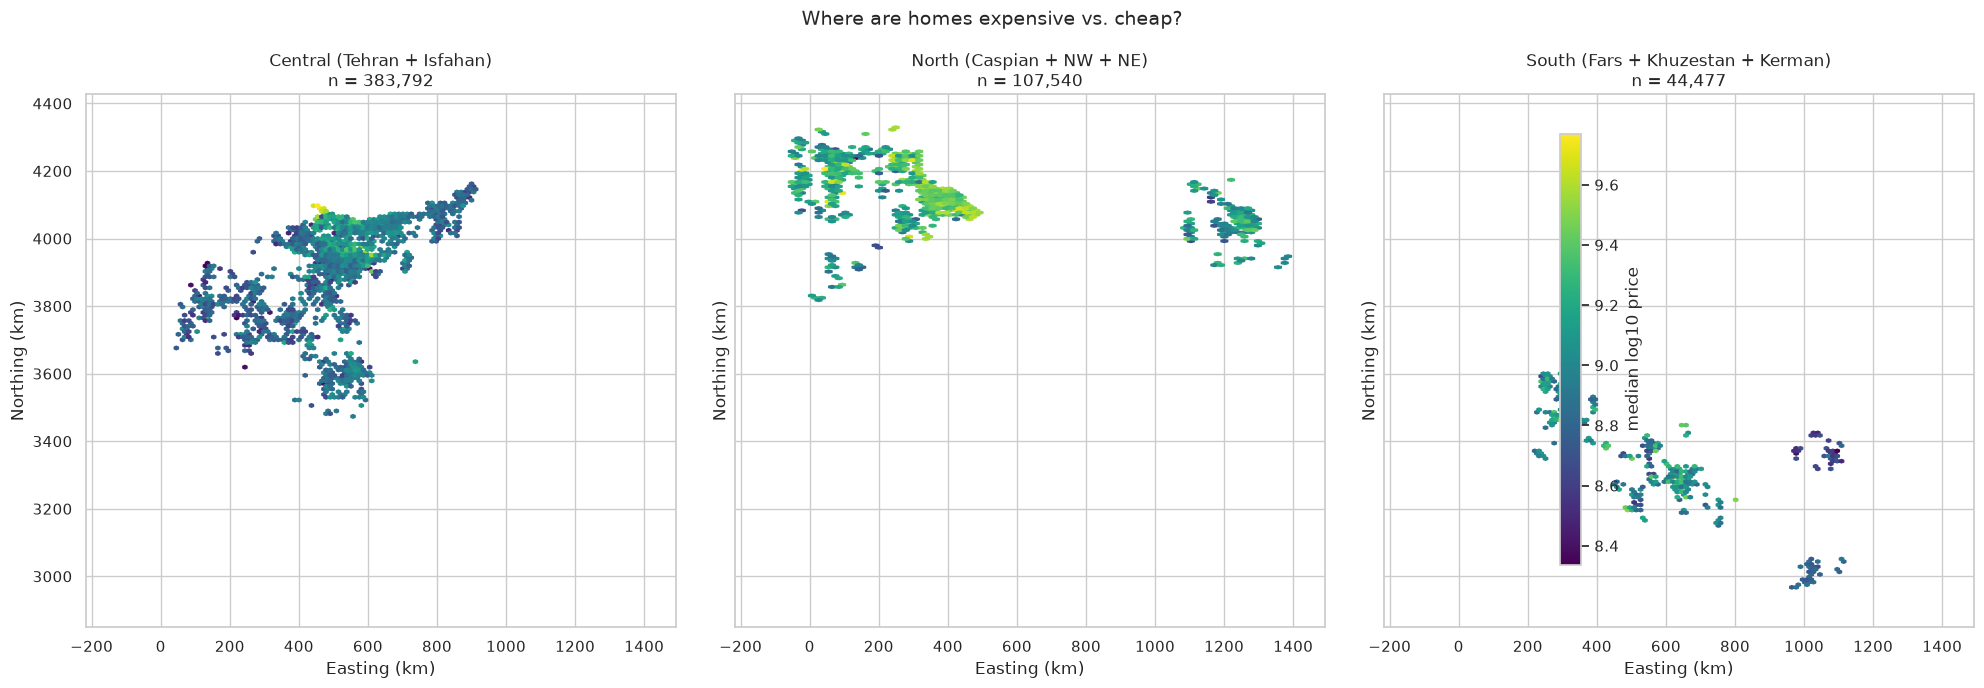

In [39]:
import matplotlib.colors as mcolors

fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharex=True, sharey=True)

for ax, cid in zip(axes, [0, 1, 2]):
    sub = clean_df[clean_df["cluster"] == cid]
    hb = ax.hexbin(sub["utm_x_km"], sub["utm_y_km"],
                   C=sub["log_price"],
                   gridsize=80,
                   cmap="viridis",
                   reduce_C_function=np.median,
                   mincnt=5)
    ax.set_title(f"{CLUSTER_NAMES[cid]}\nn = {len(sub):,}")
    ax.set_xlabel("Easting (km)")
    ax.set_ylabel("Northing (km)")

fig.colorbar(hb, ax=axes, label="median log10 price", shrink=0.8)
fig.suptitle("Where are homes expensive vs. cheap?", fontsize=14)
plt.tight_layout()
plt.show()

In [40]:
def top_cities(s, k=3):
    return ", ".join(f"{c} ({n:,})" for c, n in s.value_counts().head(k).items())

summary = (
    clean_df[clean_df["cluster"] != -1]
    .groupby("cluster")
    .agg(
        n                = ("log_price", "size"),
        median_price_rial= ("target_price", "median"),
        mean_price_rial  = ("target_price", "mean"),
        mean_x_km        = ("utm_x_km", "mean"),
        mean_y_km        = ("utm_y_km", "mean"),
        top_3_cities     = ("city_slug", top_cities),
    )
    .round(0)
)
summary.index = [CLUSTER_NAMES[c] for c in summary.index]
display(summary)

,n,median_price_rial,mean_price_rial,mean_x_km,mean_y_km,top_3_cities
Central (Tehran + Isfahan),383792,1.800000e+09,4.494500e+09,511.0,3917.0,"tehran (132,912), karaj (33,723), isfahan (21,..."
North (Caspian + NW + NE),107540,1.416667e+09,2.549984e+09,621.0,4117.0,"mashhad (33,244), tabriz (14,598), rasht (10,802)"
South (Fars + Khuzestan + Kerman),44477,1.150000e+09,2.417577e+09,568.0,3340.0,"shiraz (16,699), ahvaz (7,604), kerman (2,432)"


<div dir="rtl" align="right">

## سه منطقه‌ی کلان نهایی

در نهایت ۹ خوشه‌ی میانی به ۳ منطقه‌ی کلان نگاشت شدند:

- **مرکزی:** تهران + اصفهان و شهرهای اطراف  
- **شمالی:** استان‌های خزری + شمال‌غرب + شمال‌شرق  
- **جنوبی:** فارس + خوزستان + کرمان + هرمزگان  

بیشترین حجم داده در منطقه‌ی مرکزی قرار دارد و کمترین حجم در منطقه‌ی جنوبی.  
این نگاشت دستی انجام شده تا خروجی برای تحلیل قیمت مسکن قابل تفسیرتر باشد.

</div>

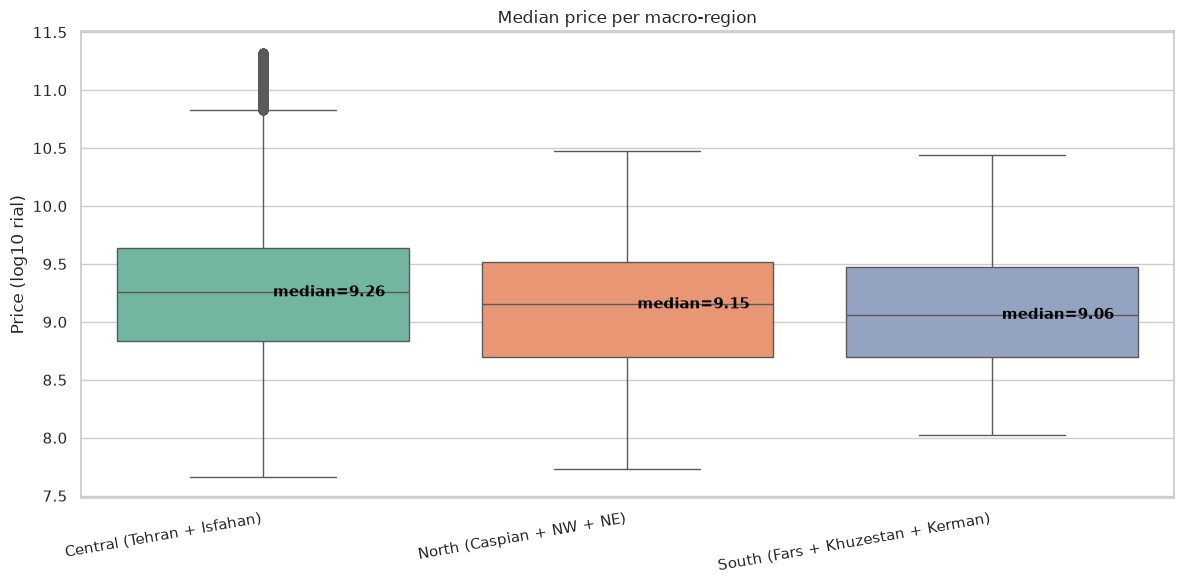

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(data=plot_data, x="region", y="log_price",
            hue="region", palette="Set2", legend=False, ax=ax)

medians = plot_data.groupby("region")["log_price"].median()
for i, (region, med) in enumerate(medians.items()):
    ax.text(i, med, f"  median={med:.2f}", va="center", fontsize=11,
            color="black", fontweight="bold")

ax.set_xlabel("")
ax.set_ylabel("Price (log10 rial)")
ax.set_title("Median price per macro-region")
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

## ذخیره‌ی خروجی نهایی

در این بخش، دیتافریم نهایی همراه با ستون `cluster` ذخیره می‌شود.  
این ستون سه منطقه‌ی کلان را نشان می‌دهد و می‌تواند برای مدل‌سازی قیمت یا تحلیل‌های منطقه‌ای استفاده شود.

</div>

In [44]:
# Minimal: just cluster labels
clean_df[["cluster"]].to_parquet("~/divar_clusters.parquet")

# Full: everything with cluster column
clean_df.to_parquet("~/divar_with_clusters.parquet", index=False)

print(f"Saved {len(clean_df):,} rows")
print(clean_df["cluster"].value_counts().sort_index())

Saved 591,395 rows
cluster
-1     55586
 0    383792
 1    107540
 2     44477
Name: count, dtype: int64
